# CREDIT CARD FRAUD ANALYSIS

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df= pd.read_csv(r"C:\Users\LENOVO\Desktop\Projects\Credit card Fraud\credit_card_fraud_2026.csv", encoding= "unicode_escape")

#### METADATA

In [3]:
df.columns

Index(['transaction_id', 'amount_usd', 'merchant_category', 'card_type',
       'auth_method', 'channel', 'device_type', 'is_foreign_transaction',
       'hours_since_last_txn', 'txn_count_last_24h', 'distance_from_home_km',
       'card_age_months', 'customer_age', 'account_balance_usd',
       'is_new_merchant', 'used_vpn', 'ip_country_mismatch',
       'billing_shipping_mismatch', 'cvv_retry_count', 'velocity_score',
       'time_of_day_hour', 'day_of_week', 'is_ai_generated_scam_attempt',
       'merchant_risk_score', 'prior_disputes', 'is_fraud'],
      dtype='object')

In [4]:
df.dtypes

transaction_id                    int64
amount_usd                      float64
merchant_category                object
card_type                        object
auth_method                      object
channel                          object
device_type                      object
is_foreign_transaction             bool
hours_since_last_txn            float64
txn_count_last_24h                int64
distance_from_home_km           float64
card_age_months                   int64
customer_age                      int64
account_balance_usd             float64
is_new_merchant                    bool
used_vpn                           bool
ip_country_mismatch                bool
billing_shipping_mismatch          bool
cvv_retry_count                   int64
velocity_score                  float64
time_of_day_hour                  int64
day_of_week                       int64
is_ai_generated_scam_attempt       bool
merchant_risk_score             float64
prior_disputes                    int64


In [5]:
df.tail(10)

,transaction_id,amount_usd,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,hours_since_last_txn,txn_count_last_24h,...,ip_country_mismatch,billing_shipping_mismatch,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,is_ai_generated_scam_attempt,merchant_risk_score,prior_disputes,is_fraud
19990,19991,651.50,Travel,Visa,OTP,Contactless,Android Phone,False,28.14,1,...,True,False,0,5.8,2,4,False,47.8,0,0
19991,19992,57.70,Restaurants,Visa,PIN,Online,Windows PC,False,3.44,4,...,False,False,0,21.7,22,3,False,33.4,0,0
19992,19993,53.65,Utilities,Mastercard,3D Secure,POS,Android Phone,False,0.82,2,...,False,False,1,28.4,2,0,False,42.6,0,0
19993,19994,46.14,Healthcare,Visa,Biometric,Online,Windows PC,False,2.73,3,...,False,False,0,5.8,9,2,False,8.3,0,0
19994,19995,277.29,Gaming,Mastercard,OTP,Online,Mac,False,1.58,2,...,False,False,0,8.6,18,2,False,49.1,0,0
19995,19996,41.40,Healthcare,Mastercard,OTP,POS,Android Phone,False,8.82,2,...,False,False,0,17.3,2,3,False,29.6,1,0
19996,19997,47.92,Online Retail,Visa,OTP,POS,Android Phone,False,45.81,1,...,False,False,0,9.0,4,0,False,29.2,1,0
19997,19998,10.25,Restaurants,Visa,3D Secure,In-App,Tablet,False,20.67,0,...,False,False,1,1.0,19,5,False,22.9,0,0
19998,19999,31.34,Travel,Visa,3D Secure,Online,Android Phone,False,22.94,2,...,False,False,0,8.8,2,1,False,27.9,0,0
19999,20000,47.70,Online Retail,Mastercard,Biometric,Online,iPhone,False,1.20,6,...,False,False,0,41.9,0,6,False,14.4,0,0


In [6]:
df.isnull().sum()

transaction_id                  0
amount_usd                      0
merchant_category               0
card_type                       0
auth_method                     0
channel                         0
device_type                     0
is_foreign_transaction          0
hours_since_last_txn            0
txn_count_last_24h              0
distance_from_home_km           0
card_age_months                 0
customer_age                    0
account_balance_usd             0
is_new_merchant                 0
used_vpn                        0
ip_country_mismatch             0
billing_shipping_mismatch       0
cvv_retry_count                 0
velocity_score                  0
time_of_day_hour                0
day_of_week                     0
is_ai_generated_scam_attempt    0
merchant_risk_score             0
prior_disputes                  0
is_fraud                        0
dtype: int64

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 26 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   transaction_id                20000 non-null  int64  
 1   amount_usd                    20000 non-null  float64
 2   merchant_category             20000 non-null  object 
 3   card_type                     20000 non-null  object 
 4   auth_method                   20000 non-null  object 
 5   channel                       20000 non-null  object 
 6   device_type                   20000 non-null  object 
 7   is_foreign_transaction        20000 non-null  bool   
 8   hours_since_last_txn          20000 non-null  float64
 9   txn_count_last_24h            20000 non-null  int64  
 10  distance_from_home_km         20000 non-null  float64
 11  card_age_months               20000 non-null  int64  
 12  customer_age                  20000 non-null  int64  
 13  a

## FEATURE ENGINEERING

#### Creating New Columns

#### 1. Creating Age Groups


In [8]:
#print(min(df["customer_age"]))

bins=[-1,20,40,60,80,100]
labels=['young','adult','middle-aged','old','senior']

df['age_group']= pd.cut(df['customer_age'],bins=bins,labels=labels)
print (df [['customer_age','age_group']])

       customer_age    age_group
0                25        adult
1                33        adult
2                59  middle-aged
3                28        adult
4                36        adult
...             ...          ...
19995            20        young
19996            74          old
19997            65          old
19998            45  middle-aged
19999            54  middle-aged

[20000 rows x 2 columns]


#### 2.Time of the Day

In [9]:
bins=[-1,6,12,18,24]
labels= ['morning','afternoon','evening','night']
df["time_of_day"]= pd.cut(df['time_of_day_hour'], bins=bins,labels=labels, right=False)
print (df [['time_of_day_hour',"time_of_day"]])

       time_of_day_hour time_of_day
0                    18       night
1                    12     evening
2                     5     morning
3                    22       night
4                     2     morning
...                 ...         ...
19995                 2     morning
19996                 4     morning
19997                19       night
19998                 2     morning
19999                 0     morning

[20000 rows x 2 columns]


#### 3. Velocity score

In [10]:
bins = [-1, 20, 40, 60, 80, 100]
labels = ['Very Low', 'Low', 'Medium', 'High', 'Very High']

df['velocity_group'] = pd.cut(
    df['velocity_score'],
    bins=bins,
    labels=labels
)
print (df [['velocity_score',"velocity_group"]])

       velocity_score velocity_group
0                 0.1       Very Low
1                25.8            Low
2                42.3         Medium
3                28.9            Low
4                 3.9       Very Low
...               ...            ...
19995            17.3       Very Low
19996             9.0       Very Low
19997             1.0       Very Low
19998             8.8       Very Low
19999            41.9         Medium

[20000 rows x 2 columns]


#### 4. Value of Transactions

In [11]:
df["transaction_size"]= np.where(df['amount_usd']<1000, "low","high")
print (df [['amount_usd',"transaction_size"]])

       amount_usd transaction_size
0           42.86              low
1            4.75              low
2           77.18              low
3            1.69              low
4          261.68              low
...           ...              ...
19995       41.40              low
19996       47.92              low
19997       10.25              low
19998       31.34              low
19999       47.70              low

[20000 rows x 2 columns]


#### 5. Day of week

In [12]:
day_mapping= {0: 'Monday',
    1: 'Tuesday',
    2: 'Wednesday',
    3: 'Thursday',
    4: 'Friday',
    5: 'Saturday',
    6: 'Sunday'}
df['day_name']= df['day_of_week'].map(day_mapping)
print(df[['day_of_week','day_name']])

       day_of_week  day_name
0                3  Thursday
1                4    Friday
2                0    Monday
3                6    Sunday
4                4    Friday
...            ...       ...
19995            3  Thursday
19996            0    Monday
19997            5  Saturday
19998            1   Tuesday
19999            6    Sunday

[20000 rows x 2 columns]


#### 6. Account Balance Classification

In [13]:
bins=[-1,45000,90000,135000]
labels= ['low','medium','high']
df["remaining_balance"]= pd.cut(df['account_balance_usd'], bins=bins,labels=labels, right=False)
print (df [['account_balance_usd',"remaining_balance"]])

       account_balance_usd remaining_balance
0                  1080.71               low
1                  4463.72               low
2                   366.25               low
3                  1345.29               low
4                  4192.59               low
...                    ...               ...
19995               750.90               low
19996              2666.73               low
19997               284.25               low
19998             14609.39               low
19999              6682.84               low

[20000 rows x 2 columns]


#### 7. Frequency of Transactions

In [14]:
bins=[-1,4,8,12]
labels=['rare','often',' very frequent']
df['transaction_frequency']= pd.cut(df['txn_count_last_24h'], bins=bins,labels=labels)
print(df[['txn_count_last_24h','transaction_frequency']])

       txn_count_last_24h transaction_frequency
0                       2                  rare
1                       2                  rare
2                       5                 often
3                       6                 often
4                       2                  rare
...                   ...                   ...
19995                   2                  rare
19996                   1                  rare
19997                   0                  rare
19998                   2                  rare
19999                   6                 often

[20000 rows x 2 columns]


#### 8. Distance From Home

In [15]:
bins=[-1,60,120,180,240]
labels=['very_near', 'near', 'mid_way', "far"]
df['distance_group']= pd.cut(df['distance_from_home_km'],bins=bins,labels=labels)
print(df[['distance_from_home_km', 'distance_group']])

       distance_from_home_km distance_group
0                      22.35      very_near
1                      35.28      very_near
2                       9.82      very_near
3                      19.72      very_near
4                      17.68      very_near
...                      ...            ...
19995                  18.13      very_near
19996                   8.97      very_near
19997                  48.67      very_near
19998                  19.05      very_near
19999                  52.65      very_near

[20000 rows x 2 columns]


## EXPLORATORY DATA ANALYSIS

#### A) CUSTOMER ANALYSIS

In [16]:
#1. Fraud Percentage 

fraud_percent = df['is_fraud'].mean()*100
print (f'Fraud percent:{fraud_percent:.2f}%') 


Fraud percent:1.70%


In [17]:
#2. Legitimate percentage

legitimate_percent= 100- fraud_percent
print (f'Legitimate percent:{legitimate_percent:.2f}%')


Legitimate percent:98.31%


In [18]:
#3. Which customer age group experiences the highest fraud?

fraud_by_customer_agegroup= df.groupby('age_group',observed=True)['is_fraud'].mean()*100

highest_agegroup= fraud_by_customer_agegroup.idxmax()
highest_rate= fraud_by_customer_agegroup.max()

print(' Fraud agegroup:' ,fraud_by_customer_agegroup)
print('Highest fraud agegroup: ',highest_agegroup)
print(f'Fraud rate: {highest_rate:.2f}%')


#hence we can say that Senio age_group is most affected by fraud 

 Fraud agegroup: age_group
young          1.277955
adult          1.505236
middle-aged    1.575796
old            2.034653
senior         2.243590
Name: is_fraud, dtype: float64
Highest fraud agegroup:  senior
Fraud rate: 2.24%


In [19]:
#4. Do customers with low account balances experience more fraud?
fraud_based_on_account_balance= df.groupby('remaining_balance',observed=True)['is_fraud'].mean()*100
highest_fraud_rate= fraud_based_on_account_balance. max()
highest_fraud_account= fraud_based_on_account_balance.idxmax()


print ('Fraud by account balance: ',fraud_based_on_account_balance)
print ('Highest account balance type: ', highest_fraud_account)
print (f'Highest rate: {highest_fraud_rate:.2f}%')

# Yes, customers with low balances experience more fraud

Fraud by account balance:  remaining_balance
low       1.696442
medium    0.000000
high      0.000000
Name: is_fraud, dtype: float64
Highest account balance type:  low
Highest rate: 1.70%


In [20]:
#5. Does transaction frequency influence fraud?
fraud_based_on_frequency= df.groupby('transaction_frequency',observed=True)['is_fraud'].mean()*100
highest_fraud_rate= fraud_based_on_frequency. max()
highest_fraud_frequency= fraud_based_on_frequency.idxmax()


print ('Fraud by frequency: ',fraud_based_on_frequency)
print ('Highest account balance type: ', highest_fraud_frequency)
print (f'Highest rate: {highest_fraud_rate:.2f}%')

# Yes, transaction frequency is directly proportional to fraud


Fraud by frequency:  transaction_frequency
rare              1.362677
often             2.766706
 very frequent    7.692308
Name: is_fraud, dtype: float64
Highest account balance type:   very frequent
Highest rate: 7.69%


#### B) TRANSACTION ANALYSIS

In [21]:
#1. What is the average fraud transaction amount?
avg_amount = (df.groupby('is_fraud')['amount_usd'].mean()*100).round(2).reset_index(name='Avg_Fraud_amt')

print(avg_amount)


   is_fraud  Avg_Fraud_amt
0         0       13158.27
1         1       18124.99


In [22]:
#2.Are high-value transactions more fraudulent?
fraud_based_on_value= df.groupby('transaction_size',observed=True)['is_fraud'].mean()*100
highest_fraud_rate= fraud_based_on_value. max()
highest_fraud_value= fraud_based_on_value.idxmax()


print ('Fraud by value: ',fraud_based_on_value)
print ('Highest value: ', highest_fraud_value)
print (f'Highest rate: {highest_fraud_rate:.2f}%')

# Yes high value trasactions i.e. those above 1000 are more fraudulent

Fraud by value:  transaction_size
high    3.716216
low     1.664637
Name: is_fraud, dtype: float64
Highest value:  high
Highest rate: 3.72%


In [23]:
#3. What time of day has the highest fraud rate?
fraud_based_on_time_of_day= df.groupby('time_of_day',observed=True)['is_fraud'].mean()*100
highest_fraud_rate= fraud_based_on_time_of_day. max()
highest_fraud_time= fraud_based_on_time_of_day.idxmax()


print ('Fraud by time: ',fraud_based_on_time_of_day)
print ('Highest fraud time: ', highest_fraud_time)
print (f'Highest rate: {highest_fraud_rate:.2f}%')

# Morning has the highest number of frauds


Fraud by time:  time_of_day
morning      2.755985
afternoon    1.440162
evening      1.282304
night        1.312127
Name: is_fraud, dtype: float64
Highest fraud time:  morning
Highest rate: 2.76%


In [24]:
#4. Which day of the week records the most fraud?
fraud_based_on_day= df.groupby('day_name',observed=True)['is_fraud'].mean()*100
highest_fraud_rate= fraud_based_on_day. max()
highest_fraud_day= fraud_based_on_day.idxmax()


print ('Fraud by day: ',fraud_based_on_day)
print ('Highest fraud day: ', highest_fraud_day)
print (f'Highest rate: {highest_fraud_rate:.2f}%')

# Sunday= most frauds happen



Fraud by day:  day_name
Friday       1.388889
Monday       1.614602
Saturday     1.621622
Sunday       2.088326
Thursday     1.886121
Tuesday      1.720578
Wednesday    1.539000
Name: is_fraud, dtype: float64
Highest fraud day:  Sunday
Highest rate: 2.09%


#### C) MERCHANT ANALYSIS

In [25]:
#1. Which merchant category has the highest fraud rate?

highest_fraud_by_merchant= df.groupby('merchant_category')['is_fraud'].mean().mul(100).round(2).sort_values(ascending=False).reset_index(name='fraud_pct')
#highest_fraud_rate= highest_fraud_by_merchant.max()
#highest_fraud_merchant= highest_fraud_by_merchant.idxmax()

#print ('Fraud by merchant: ', highest_fraud_by_merchant)
#print('Highest Merchant:', highest_fraud_merchant)
#print(f'Highest Rate: {highest_fraud_rate:.2f}%')
print (highest_fraud_by_merchant)

# CRYPTO EXCHANGE = highest

   merchant_category  fraud_pct
0    Crypto Exchange       4.99
1         Gift Cards       4.38
2             Gaming       3.67
3        Electronics       2.36
4          Streaming       2.08
5          Utilities       1.88
6         Healthcare       1.29
7          Groceries       1.23
8               Fuel       1.21
9        Restaurants       1.14
10            Travel       1.13
11     Online Retail       0.94


In [26]:
#2. Which merchant categories process the highest transaction amounts?

highest_transaction_amount_by_merchant= df.groupby('merchant_category')['amount_usd'].sum().sort_values(ascending=False).reset_index(name= 'tran_amount')
highest_amount= highest_transaction_amount_by_merchant['tran_amount'].max()
merchant = highest_transaction_amount_by_merchant.loc[
    highest_transaction_amount_by_merchant['tran_amount'].idxmax(),
    'merchant_category'
]

#print ('Highest Transaction amount by merchant: ',highest_transaction_amount_by_merchant)
print(highest_transaction_amount_by_merchant)
print(f'Highest Amount :{highest_amount:.2f}')
print("Highest Transaction Merchant: ", merchant)


   merchant_category  tran_amount
0             Travel    628217.75
1        Electronics    613888.07
2      Online Retail    283801.03
3          Groceries    266595.96
4    Crypto Exchange    200373.44
5        Restaurants    197226.96
6          Utilities    108113.40
7         Healthcare    101889.48
8             Gaming     86482.59
9               Fuel     84087.73
10        Gift Cards     54977.25
11         Streaming     22838.28
Highest Amount :628217.75
Highest Transaction Merchant:  Travel


In [27]:
#3. Are new merchants riskier?
new_merchants_risk= df.groupby('is_new_merchant')['is_fraud'].mean().mul(100).round(2).reset_index(name='fraud_rate_pct')
#new_merchants_risk= (df.groupby('is_new_merchant')['is_fraud'].mean()*100).round(2).reset_index(name='fraud_rate_pct')


#print ('Merchant Newness: ',new_merchants_risk)
print(new_merchants_risk)

# Yes, new merchants are riskier


   is_new_merchant  fraud_rate_pct
0            False            1.16
1             True            3.50


In [28]:
#. Does merchant risk score correlate with fraud?
correlation= df['merchant_risk_score'].corr(df['is_fraud'])

print('Correlation: ',round(correlation,2))

Correlation:  0.11


##### D) AUTHENTICATION ANALYSIS

In [29]:
#1. Which authentication method has the lowest fraud?
lowest_fraud_by_authentication= df.groupby('auth_method')['is_fraud'].mean().mul(100).round(2).sort_values().reset_index(name='Fraud_pct')
print(lowest_fraud_by_authentication)

# Biometric= lowest fraud

         auth_method  Fraud_pct
0          Biometric       0.78
1                PIN       1.15
2          3D Secure       1.55
3                OTP       1.57
4  No Authentication       4.44


In [30]:
#2. Does CVV retry count increase fraud probability?
fraud_cvv_retry= df.groupby('cvv_retry_count')['is_fraud'].mean().mul(100).round(2).sort_values(ascending=False).reset_index(name='Fraud_pct')
print(fraud_cvv_retry)

#2 tries has the highest probability. Transactions with more CVV retries generally have higher fraud rates. The highest fraud rate is observed at 2 retries (16.14%), while 3 retries also have a high fraud rate (13.33%).

   cvv_retry_count  Fraud_pct
0                2      16.14
1                3      13.33
2                1       4.65
3                0       0.92


#### E) DEVICE AND CHANNEL ANALYSIS

In [31]:
#1.Which device type records the most fraud?
fraud_device= df.groupby('device_type')['is_fraud'].mean().mul(100).round(2).sort_values(ascending=False).reset_index(name='Fraud_pct')
print(fraud_device)

# Android phone= records most frauds

     device_type  Fraud_pct
0  Android Phone       1.89
1         Tablet       1.89
2            Mac       1.84
3    ATM Machine       1.79
4    Smart Watch       1.79
5   POS Terminal       1.71
6         iPhone       1.65
7     Windows PC       1.11


In [32]:
#2.Which transaction channel is most vulnerable?
fraud_channel= df.groupby('channel')['is_fraud'].mean().mul(100).round(2).sort_values(ascending=False).reset_index(name='Fraud_pct')
print(fraud_channel)

# Online= Most vulnerable

       channel  Fraud_pct
0       Online       1.98
1          ATM       1.82
2       In-App       1.61
3          POS       1.52
4  Contactless       1.41


#### F) GEOGRAPHIC ANALYSIS

In [33]:
#1.Are foreign transactions more fraudulent?
fraud_by_residence= df.groupby('is_foreign_transaction')['is_fraud'].mean().mul(100).round(2).sort_values(ascending=False).reset_index(name='Fraud_pct')
print(fraud_by_residence)

# Yes

   is_foreign_transaction  Fraud_pct
0                    True       5.89
1                   False       1.42


In [34]:
#2. Does VPN usage increase fraud?
fraud_by_VPN_use= df.groupby('used_vpn')['is_fraud'].mean().mul(100).round(2).sort_values(ascending=False).reset_index(name='Fraud_pct')
print(fraud_by_VPN_use)

# Yes

   used_vpn  Fraud_pct
0      True       4.38
1     False       1.44


In [35]:
#3. Does IP-country mismatch indicate fraud?
fraud_by_ip_country_mismatch= df.groupby('ip_country_mismatch')['is_fraud'].mean().mul(100).round(2).sort_values(ascending=False).reset_index(name='Fraud_pct')
print(fraud_by_ip_country_mismatch)

# Yes

   ip_country_mismatch  Fraud_pct
0                 True       7.80
1                False       1.32


In [36]:
#4. Does billing/shipping mismatch increase fraud?
fraud_by_billing_shipping_mismatch= df.groupby('billing_shipping_mismatch')['is_fraud'].mean().mul(100).round(2).sort_values(ascending=False).reset_index(name='Fraud_pct')
print(fraud_by_billing_shipping_mismatch)

# Yes

   billing_shipping_mismatch  Fraud_pct
0                       True       7.79
1                      False       1.42


#### G) BEHAVIORAL ANALYSIS

In [37]:
#1. Does velocity score predict fraud?
fraud_by_velocity= df.groupby('velocity_group', observed=True)['is_fraud'].mean().mul(100).round(2).sort_values(ascending=False).reset_index(name='Fraud_pct')
print(fraud_by_velocity)

# Yes

  velocity_group  Fraud_pct
0           High      10.14
1         Medium       4.98
2            Low       2.25
3       Very Low       0.87


In [38]:
#2. Do AI-generated scam attempts lead to more fraud?

fraud_by_ai_attempt= df.groupby('is_ai_generated_scam_attempt')['is_fraud'].mean().mul(100).round(2).sort_values(ascending=False).reset_index(name='Fraud_pct')
print(fraud_by_ai_attempt)

# YES


   is_ai_generated_scam_attempt  Fraud_pct
0                          True       9.07
1                         False       1.55


In [39]:
#3. Do customers with previous disputes commit more fraud?
fraud_by_prior_disputes= df.groupby('prior_disputes')['is_fraud'].mean().mul(100).round(2).sort_values(ascending=False).reset_index(name='Fraud_pct')
print(fraud_by_prior_disputes)

# Yes

   prior_disputes  Fraud_pct
0               4      33.33
1               2       3.79
2               1       1.87
3               0       1.56
4               3       0.00


In [40]:
#4. Does distance from home increase fraud?
fraud_by_distance= df.groupby('distance_group',observed=True)['is_fraud'].mean().mul(100).round(2).sort_values(ascending=False).reset_index(name='Fraud_pct')

#fraud_by_dist= df.groupby('distance_group')['is_fraud'].mean().mul(100)
#fraud_rate= fraud_by_dist.max()
#print('Fraud_Rate: ',round(fraud_rate,2))

print(fraud_by_distance)

# No

  distance_group  Fraud_pct
0      very_near       1.71
1           near       1.50
2        mid_way       1.15
3            far       0.00


## VISUALISATIONS

In [41]:
df_visual=df.copy()

In [42]:
df.columns

Index(['transaction_id', 'amount_usd', 'merchant_category', 'card_type',
       'auth_method', 'channel', 'device_type', 'is_foreign_transaction',
       'hours_since_last_txn', 'txn_count_last_24h', 'distance_from_home_km',
       'card_age_months', 'customer_age', 'account_balance_usd',
       'is_new_merchant', 'used_vpn', 'ip_country_mismatch',
       'billing_shipping_mismatch', 'cvv_retry_count', 'velocity_score',
       'time_of_day_hour', 'day_of_week', 'is_ai_generated_scam_attempt',
       'merchant_risk_score', 'prior_disputes', 'is_fraud', 'age_group',
       'time_of_day', 'velocity_group', 'transaction_size', 'day_name',
       'remaining_balance', 'transaction_frequency', 'distance_group'],
      dtype='object')

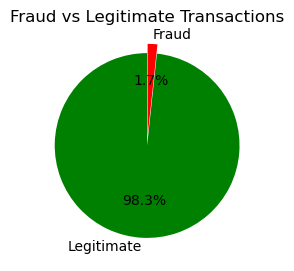

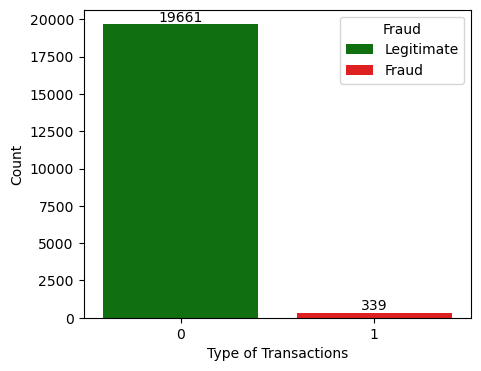

In [43]:
#1.  Fraud Vs Legit

fraud_count= df_visual['is_fraud'].value_counts()
plt.figure(figsize=(3,3))
plt.pie(fraud_count, labels=['Legitimate', 'Fraud'],colors=['green', 'red'],explode=[0,0.1],autopct='%1.1f%%',
    startangle=90)
plt.title('Fraud vs Legitimate Transactions')
plt.show()


plt.figure(figsize=(5,4))
ax= sns.countplot(x= 'is_fraud', data=df_visual, hue='is_fraud', palette=['green','red'])
plt.xlabel('Type of Transactions')
plt.ylabel('Count')
plt.legend(title='Fraud', labels=['Legitimate', 'Fraud'])
for bars in ax.containers:
    ax.bar_label(bars)
    

Text(0, 0.5, 'No. of Transactions')

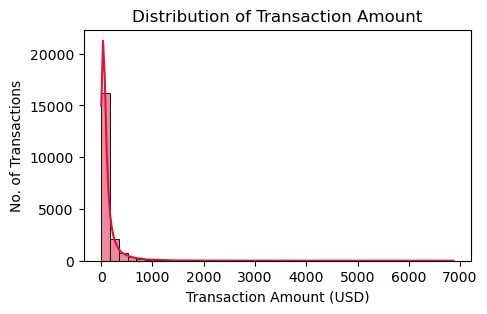

In [44]:
#2. Transaction Amount Dist.

#plt.figure(figsize=(5,3))
#plt.hist(df_visual['amount_usd'],bins=40,color='skyblue')
#plt.title('Transaction Amount Distribution')
#plt.xlabel('Transaction Amount')
#plt.ylabel('No. of Transactions')
#plt.show())


plt.figure(figsize=(5,3))
sns.histplot(data= df_visual, x= 'amount_usd', bins=40, kde= True, color= 'crimson')

plt.title('Distribution of Transaction Amount')
plt.xlabel('Transaction Amount (USD)')
plt.ylabel('No. of Transactions')


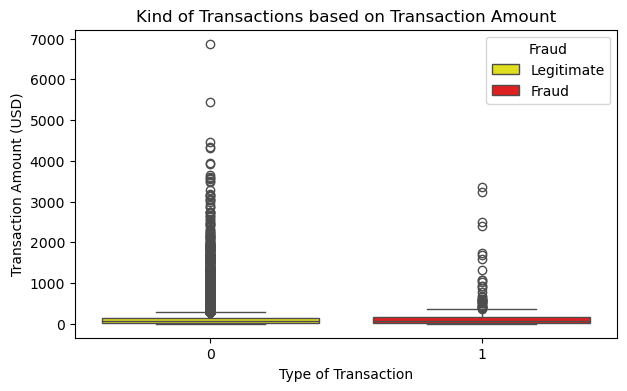

In [45]:
#3.Fraud by Amount

plt.figure(figsize=(7,4))
sns.boxplot(data=df_visual, x='is_fraud', y='amount_usd', hue= 'is_fraud', palette=['yellow', 'red'])
plt.title('Kind of Transactions based on Transaction Amount')
plt.xlabel('Type of Transaction')
plt.ylabel('Transaction Amount (USD)')
plt.legend(title='Fraud', labels=['Legitimate', 'Fraud'])

          

In [46]:
import warnings
warnings.filterwarnings("ignore")

Text(0, 0.5, 'Fraud %')

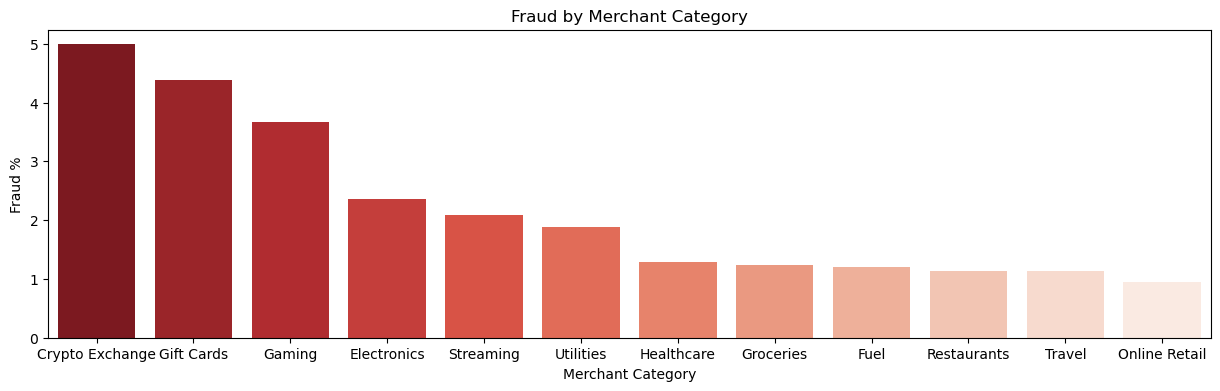

In [47]:
#4. Fraud by Merchant Category

#fraud_by_merchant = (df_visual.groupby('merchant_category')['is_fraud'].mean().mul(100).round(2).reset_index(name='Fraud_pct'))
plt.figure(figsize=(15,4))
#sns.barplot(data= fraud_by_merchant,x= 'merchant_category',y= 'Fraud_pct',palette='Reds')
sns.barplot(data= highest_fraud_by_merchant,x= 'merchant_category',y= 'fraud_pct',palette='Reds_r')
plt.title('Fraud by Merchant Category')
plt.xlabel('Merchant Category')
plt.ylabel('Fraud %')

Text(0, 0.5, 'Fraud %')

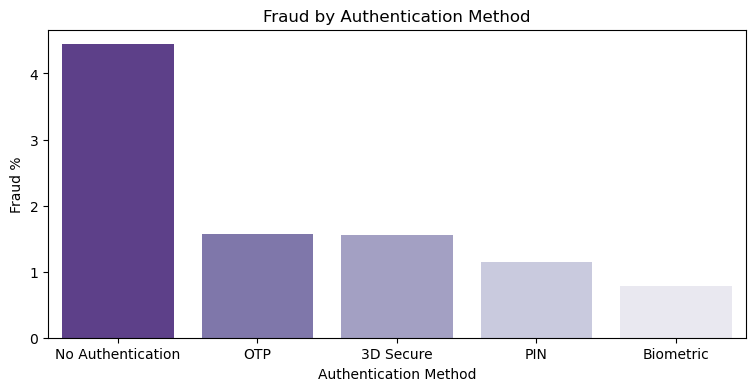

In [48]:
#5. Fraud by Authentication Method

fraud_by_authentication= df.groupby('auth_method')['is_fraud'].mean().mul(100).round(2).sort_values(ascending= False).reset_index(name='Fraud_pct')
plt.figure(figsize=(9,4))
sns.barplot(data= fraud_by_authentication,x= 'auth_method',y= 'Fraud_pct',palette='Purples_r')
plt.title('Fraud by Authentication Method')
plt.xlabel('Authentication Method')
plt.ylabel('Fraud %')

Text(0, 0.5, 'Fraud %')

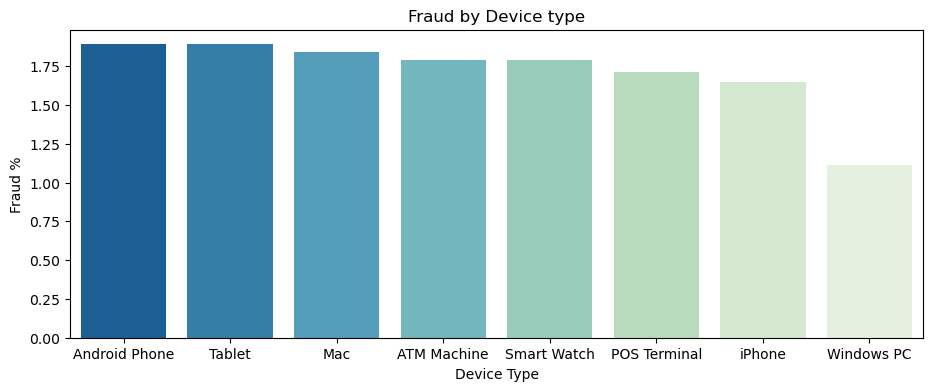

In [49]:
#6. Fraud by Device

fraud_by_device= df_visual.groupby('device_type')['is_fraud'].mean().mul(100).round(2).sort_values(ascending=False).reset_index(name='Fraud_pct')
plt.figure(figsize=(11,4))
sns.barplot(data= fraud_by_device, x='device_type',y='Fraud_pct',palette='GnBu_r')
plt.title('Fraud by Device type')
plt.xlabel('Device Type')
plt.ylabel('Fraud %')

Text(0, 0.5, 'Fraud %')

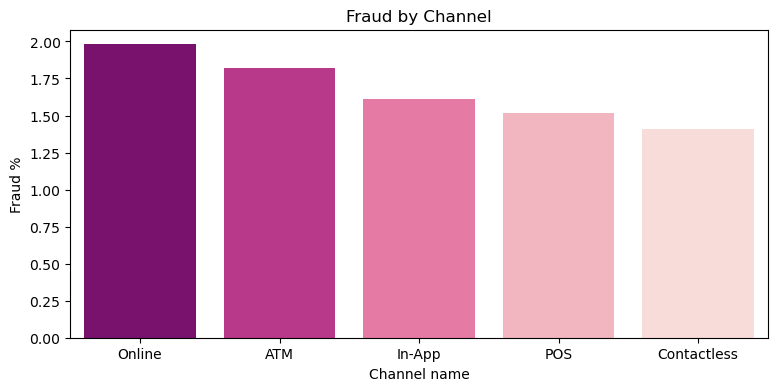

In [50]:
#7. Fraud by Channel

fraud_by_channel= df_visual.groupby('channel')['is_fraud'].mean().mul(100).round(2).sort_values(ascending=False).reset_index(name='Fraud_pct')
plt.figure(figsize=(9,4))
sns.barplot(data= fraud_by_channel, x='channel',y='Fraud_pct',palette='RdPu_r')
plt.title('Fraud by Channel')
plt.xlabel('Channel name')
plt.ylabel('Fraud %')


Text(0, 0.5, 'Fraud %')

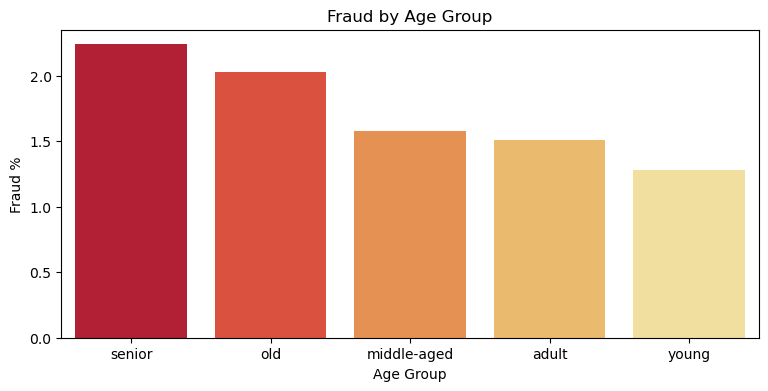

In [51]:
#8. Fraud by Age
fraud_by_customer_agegroup= df.groupby('age_group',observed=True)['is_fraud'].mean().mul(100).round(2).sort_values(ascending=False).reset_index(name='Fraud_pct')
plt.figure(figsize=(9,4))
sns.barplot(data= fraud_by_customer_agegroup, x='age_group',y='Fraud_pct',order=fraud_by_customer_agegroup['age_group'],palette='YlOrRd_r')
plt.title('Fraud by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Fraud %')


Text(0, 0.5, 'Fraud %')

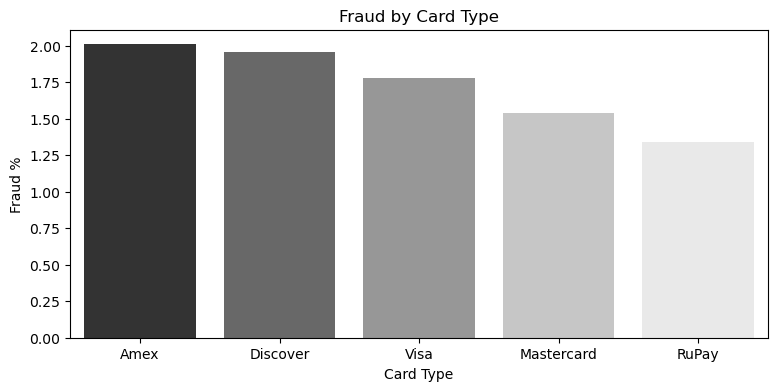

In [52]:
#9. Fraud by Card Type
fraud_by_card_type= df_visual.groupby('card_type')['is_fraud'].mean().mul(100).round(2).sort_values(ascending=False).reset_index(name='Fraud_pct')
plt.figure(figsize=(9,4))
sns.barplot(data= fraud_by_card_type, x='card_type',y='Fraud_pct',palette='Greys_r')
plt.title('Fraud by Card Type')
plt.xlabel('Card Type')
plt.ylabel('Fraud %')



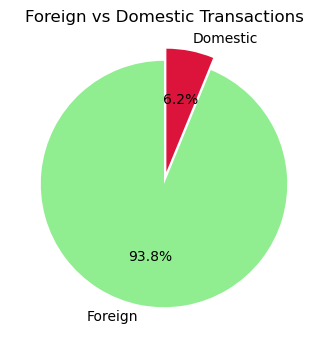

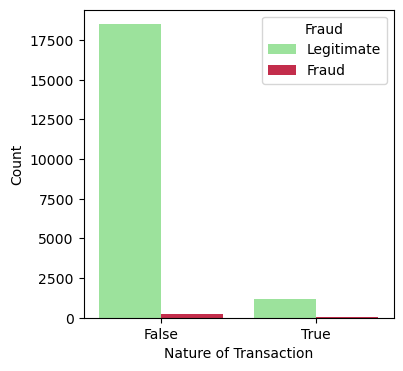

In [53]:
#10. Foreign Vs Domestic
foreign_tran_count= df_visual['is_foreign_transaction'].value_counts()
plt.figure(figsize=(4,4))
plt.pie(foreign_tran_count, labels=['Foreign', 'Domestic'],colors=['lightgreen', 'crimson'],explode=[0,0.1],autopct='%1.1f%%', startangle=90)
plt.title('Foreign vs Domestic Transactions')
plt.show()

plt.figure(figsize=(4,4))
sns.countplot(data= df_visual, x= 'is_foreign_transaction', hue= 'is_fraud', palette= ['lightgreen', 'crimson'])
plt.xlabel('Nature of Transaction')
plt.ylabel('Count')
plt.legend(title='Fraud', labels=['Legitimate', 'Fraud'])



Text(0, 0.5, 'Fraud %')

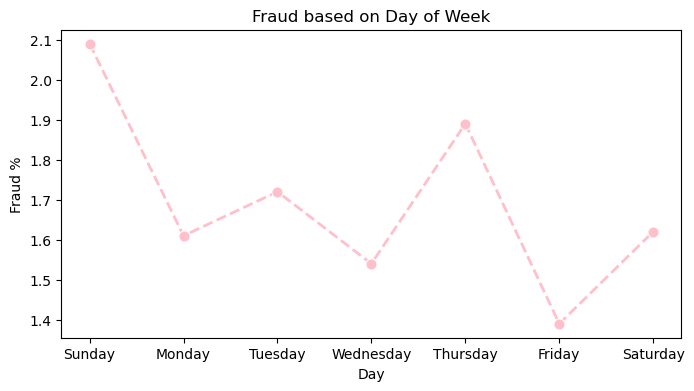

In [54]:
#11. Fraud by Day
day_order = ['Sunday','Monday','Tuesday','Wednesday',
             'Thursday','Friday','Saturday']
fraud_based_on_day= df.groupby('day_name',observed=True)['is_fraud'].mean().mul(100).round(2).reindex(day_order).reset_index(name='Fraud_pct')
plt.figure(figsize=(8,4))
sns.lineplot(data=fraud_based_on_day, x="day_name", y="Fraud_pct", color='pink', marker='o', linestyle='dashed',  linewidth=2, markersize=8)
plt.title('Fraud based on Day of Week')
plt.xlabel('Day')
plt.ylabel('Fraud %')



Text(0, 0.5, 'Fraud %')

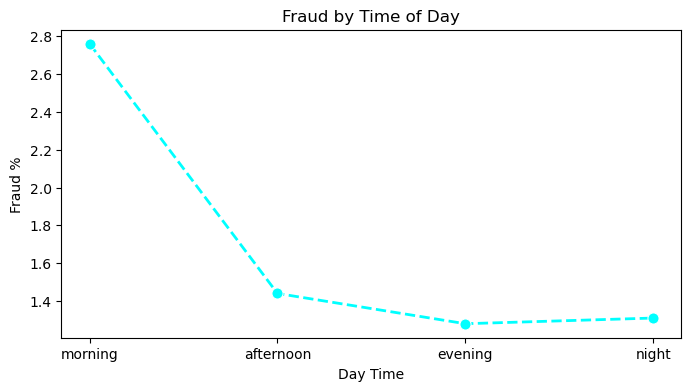

In [55]:
#12. Fraud by time of day
time_order = ['morning','afternoon','evening','night']
fraud_based_on_time_of_day= df.groupby('time_of_day',observed=True)['is_fraud'].mean().mul(100).round(2).reindex(time_order).reset_index(name='Fraud_pct')
plt.figure(figsize=(8,4))

sns.lineplot(data= fraud_based_on_time_of_day, x="time_of_day", y="Fraud_pct", color='cyan', marker='o', linestyle='dashed',  linewidth=2, markersize=8)
plt.title('Fraud by Time of Day')
plt.xlabel('Day Time')
plt.ylabel('Fraud %')



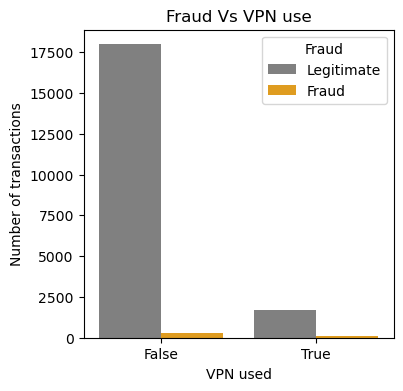

In [56]:
#13. Fraud by VPN
#fraud_by_VPN_use= df.groupby('used_vpn')['is_fraud'].mean().mul(100).round(2).sort_values(ascending=False).reset_index(name='Fraud_pct')
#plt.figure(figsize=(6,3))
#sns.barplot(data= fraud_by_VPN_use, x='used_vpn',y='Fraud_pct',palette='PuBuGn_r')

plt.figure(figsize=(4,4))
sns.countplot(data= df_visual, x= 'used_vpn', hue= 'is_fraud', palette= ['grey', 'orange'])
plt.title('Fraud Vs VPN use')
plt.xlabel('VPN used')
plt.ylabel('Number of transactions')
plt.legend(title='Fraud', labels=['Legitimate', 'Fraud'])


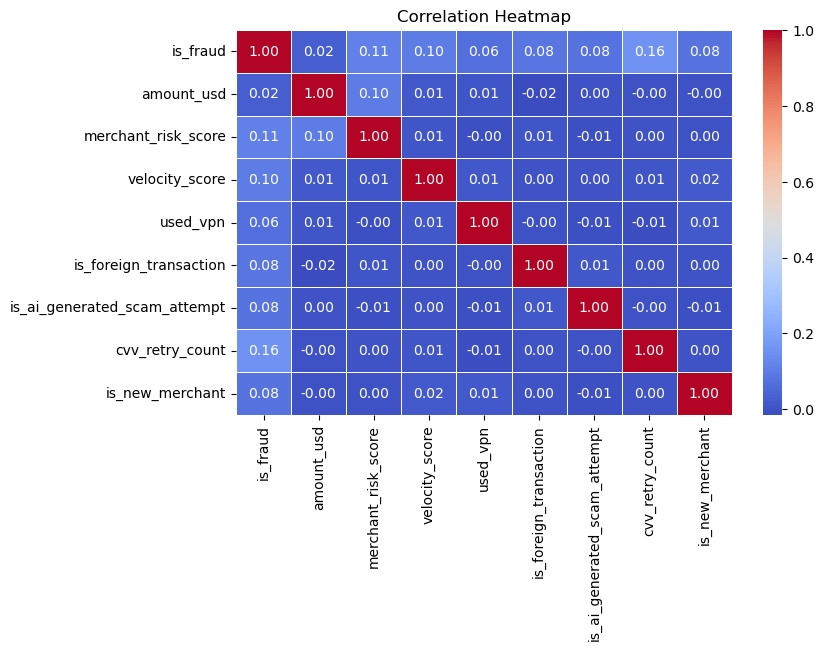

In [57]:
#14. Correaltion heatmap
corr_df = df_visual[
    ['is_fraud',
     'amount_usd',
     'merchant_risk_score',
     'velocity_score',
     'used_vpn',
     'is_foreign_transaction',
     'is_ai_generated_scam_attempt',
     'cvv_retry_count',
     'is_new_merchant']
].copy()

# Convert boolean columns to integers
bool_cols = corr_df.select_dtypes(include='bool').columns
corr_df[bool_cols] = corr_df[bool_cols].astype(int)

corr = corr_df.corr()

plt.figure(figsize=(8,5))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap')
plt.show()


In [58]:
from sqlalchemy import create_engine

username = "root"
password = "Navshree95"
host = "127.0.0.1"
port = "3306"
database = "credit_card_fraud_analysis_db"

engine = create_engine(
    f"mysql+mysqlconnector://{username}:{password}@{host}:{port}/{database}"
)

In [59]:
df.to_sql(
    "fraud_analysis",
    con=engine,
    if_exists="replace",
    index=False
)

20000